## 1. Find SUMO

In [1]:
import os, sys, shutil, random, pickle
from collections import defaultdict

SUMO_HOME = os.environ.get("SUMO_HOME")
if not SUMO_HOME:
    try:
        import sumo
        SUMO_HOME = getattr(sumo, "SUMO_HOME", None)
    except ImportError:
        pass
if not SUMO_HOME and shutil.which("sumo"):
    SUMO_HOME = os.path.dirname(os.path.dirname(os.path.realpath(shutil.which("sumo"))))
if SUMO_HOME:
    os.environ["SUMO_HOME"] = SUMO_HOME
    sys.path.append(os.path.join(SUMO_HOME, "tools"))
import traci

def sumo_binary(name):
    if SUMO_HOME:
        for candidate in (name, name + ".exe"):
            path = os.path.join(SUMO_HOME, "bin", candidate)
            if os.path.exists(path):
                return path
    return shutil.which(name) or name

print("SUMO_HOME:", SUMO_HOME)

SUMO_HOME: /opt/homebrew/opt/sumo/share/sumo


## 2. Settings

In [2]:
FOLDER = "."                                  # folder with the SUMO files
CONFIG_FILE = os.path.join(FOLDER, "accident.sumocfg")

# --- Scenario ---
CRASH_VEHICLE, HIT_VEHICLE = "crash_car", "hit_car"
CRASH_POSITION = 300.0       # m, where the accident happens (road is 600 m)
HIT_SPEED = 12.0             # m/s
ACCIDENT_DURATION = 300.0    # s
EPISODE_END = 450.0          # s, length of one episode
STEP_LENGTH = 0.5            # s, simulation step during training (faster than 0.1)

# --- Agents ---
P_SMART = 0.3                # share of cars that are learning agents
DECISION_INTERVAL = 1.0      # s between decisions
JOIN_RANGE = 50.0            # m, max gap to the vehicle ahead to join a platoon
PLATOON_TAU = 0.5            # s, time gap inside a platoon (normal cars: 1.0 s)

# --- Reward ---
W_LOCAL, W_GLOBAL = 0.5, 0.5
V_MAX = 33.33                # m/s, to normalise speed
GLOBAL_NORM = 2.0            # vehicles leaving per decision interval that counts as "1"
UNSAFE_GAP = 2.0             # m
PENALTY_UNSAFE, PENALTY_COLLISION = 1.0, 5.0

# --- Q-learning ---
N_EPISODES = 40
ALPHA, GAMMA = 0.1, 0.95
EPS_START, EPS_END = 1.0, 0.05

ACTIONS = ["keep", "slow", "join", "leave", "left"]
for name in ["accident.sumocfg", "highway.net.xml", "routes.rou.xml"]:
    print(f"{name:20s}", "OK" if os.path.exists(os.path.join(FOLDER, name)) else "MISSING")

accident.sumocfg     OK
highway.net.xml      OK
routes.rou.xml       OK


## 3. Accident (same logic as the accident notebook)

In [3]:
def new_accident():
    return {"crash_time": None, "hit_armed": False, "hit_done": False, "cleared": False}

def accident_step(acc, t, ids):
    """Advance the accident by one simulation step."""
    if not acc["cleared"]:
        for v in (CRASH_VEHICLE, HIT_VEHICLE):
            if v in ids:
                traci.vehicle.setLaneChangeMode(v, 0)

    if acc["crash_time"] is None and CRASH_VEHICLE in ids:
        if traci.vehicle.getLanePosition(CRASH_VEHICLE) >= CRASH_POSITION:
            traci.vehicle.setDecel(CRASH_VEHICLE, 9.0)
            traci.vehicle.setSpeed(CRASH_VEHICLE, 0.0)
            traci.vehicle.setColor(CRASH_VEHICLE, (255, 0, 0, 255))
            acc["crash_time"] = t

    if acc["crash_time"] is not None and not acc["hit_armed"] and HIT_VEHICLE in ids:
        traci.vehicle.setSpeedMode(HIT_VEHICLE, 0)
        traci.vehicle.setSpeed(HIT_VEHICLE, HIT_SPEED)
        traci.vehicle.setColor(HIT_VEHICLE, (255, 140, 0, 255))
        acc["hit_armed"] = True

    if acc["hit_armed"] and not acc["hit_done"] and HIT_VEHICLE in ids and CRASH_VEHICLE in ids:
        rear = traci.vehicle.getLanePosition(CRASH_VEHICLE) - traci.vehicle.getLength(CRASH_VEHICLE)
        gap = rear - traci.vehicle.getLanePosition(HIT_VEHICLE)
        if -1.0 < gap <= traci.vehicle.getSpeed(HIT_VEHICLE) * traci.simulation.getDeltaT() + 0.3:
            traci.vehicle.setSpeed(HIT_VEHICLE, 0.0)
            traci.vehicle.setColor(HIT_VEHICLE, (255, 0, 0, 255))
            acc["hit_done"] = True

    if acc["crash_time"] is not None and not acc["cleared"] and t >= acc["crash_time"] + ACCIDENT_DURATION:
        for v in (CRASH_VEHICLE, HIT_VEHICLE):
            if v in ids:
                traci.vehicle.setSpeed(v, -1)
                traci.vehicle.setSpeedMode(v, 31)
                traci.vehicle.setLaneChangeMode(v, 1621)
        acc["cleared"] = True

def accident_active(acc):
    return acc["crash_time"] is not None and not acc["cleared"]

## 4. State, actions, reward, Q-table

In [4]:
CYAN, PURPLE = (0, 200, 255, 255), (170, 60, 255, 255)

def leader_gap(v):
    leader = traci.vehicle.getLeader(v, 100.0)
    if leader is None or leader[0] == "":
        return None
    return leader[1]

def get_state(v, acc, in_platoon):
    pos = traci.vehicle.getLanePosition(v)
    speed = traci.vehicle.getSpeed(v)
    gap = leader_gap(v)
    active = accident_active(acc)

    if not active:
        dist_bin = 3                                   # no accident right now
    else:
        d = CRASH_POSITION - pos
        dist_bin = 0 if d < 50 else (1 if d < 150 else 2)
    blocked = int(active and traci.vehicle.getLaneIndex(v) == 0)
    speed_bin = 0 if speed < 5 else (1 if speed < 15 else (2 if speed < 25 else 3))
    gap_bin = 0 if gap is None or gap > 50 else (1 if gap > 20 else 2)
    return (dist_bin, blocked, speed_bin, gap_bin, int(in_platoon))

def choose_action(Q, s, epsilon):
    if random.random() < epsilon:
        return random.randrange(len(ACTIONS))
    values = Q[s]
    best = max(values)
    return random.choice([a for a, q in enumerate(values) if q == best])

def apply_action(v, a, platoon):
    name = ACTIONS[a]
    if name == "keep":
        traci.vehicle.setSpeed(v, -1)
    elif name == "slow":
        traci.vehicle.setSpeed(v, max(traci.vehicle.getSpeed(v) - 3.0, 3.0))
    elif name == "join":
        traci.vehicle.setSpeed(v, -1)
        gap = leader_gap(v)
        if v not in platoon and gap is not None and gap < JOIN_RANGE:
            traci.vehicle.setType(v, "car_platoon")
            traci.vehicle.setColor(v, PURPLE)
            platoon.add(v)
    elif name == "leave":
        traci.vehicle.setSpeed(v, -1)
        if v in platoon:
            traci.vehicle.setType(v, "car")
            traci.vehicle.setColor(v, CYAN)
            platoon.discard(v)
    elif name == "left":
        traci.vehicle.setSpeed(v, -1)
        if traci.vehicle.getLaneIndex(v) == 0:
            traci.vehicle.changeLane(v, 1, 3.0)

def get_reward(v, arrived_in_interval, colliding):
    speed = traci.vehicle.getSpeed(v)
    gap = leader_gap(v)
    r = W_LOCAL * speed / V_MAX + W_GLOBAL * arrived_in_interval / GLOBAL_NORM
    if gap is not None and gap < UNSAFE_GAP:
        r -= PENALTY_UNSAFE
    if v in colliding:
        r -= PENALTY_COLLISION
    return r

def q_update(Q, s, a, r, s_next):
    target = r if s_next is None else r + GAMMA * max(Q[s_next])
    Q[s][a] += ALPHA * (target - Q[s][a])

def new_q_table():
    return defaultdict(lambda: [0.0] * len(ACTIONS))

## 5. One episode

`control=False` = baseline: the same vehicles are marked as agents but nobody controls them (no platooning).

In [5]:
def run_episode(Q, epsilon, seed, learn=True, control=True, use_gui=False, gui_delay=100):
    random.seed(seed)
    binary = sumo_binary("sumo-gui" if use_gui else "sumo")
    cmd = [binary, "-c", CONFIG_FILE, "--start", "--seed", str(seed),
           "--collision.action", "warn", "--no-warnings", "true"]
    if use_gui:
        cmd += ["--delay", str(gui_delay)]
    else:
        cmd += ["--step-length", str(STEP_LENGTH)]
    traci.start(cmd)

    # platoon vehicle type = a copy of "car" with a short time gap
    traci.vehicletype.copy("car", "car_platoon")
    traci.vehicletype.setTau("car_platoon", PLATOON_TAU)
    traci.vehicletype.setMinGap("car_platoon", 1.5)

    acc = new_accident()
    smart, platoon = set(), set()
    memory = {}                     # agent -> (state, action) of its last decision
    depart_time, travel_times = {}, []
    arrived_in_interval, collisions = 0, 0
    next_decision = DECISION_INTERVAL
    total_reward = 0.0

    try:
        while traci.simulation.getTime() < EPISODE_END:
            traci.simulationStep()
            t = traci.simulation.getTime()
            ids = set(traci.vehicle.getIDList())

            for v in traci.simulation.getDepartedIDList():
                depart_time[v] = t
                if v.startswith("cars") and random.random() < P_SMART:
                    smart.add(v)
                    traci.vehicle.setColor(v, CYAN)
            for v in traci.simulation.getArrivedIDList():
                arrived_in_interval += 1
                if v in depart_time:
                    travel_times.append(t - depart_time[v])
                memory.pop(v, None)

            colliding = set(traci.simulation.getCollidingVehiclesIDList()) - {CRASH_VEHICLE, HIT_VEHICLE}
            collisions += len(colliding & smart)

            accident_step(acc, t, ids)

            if control and t + 1e-6 >= next_decision:
                for v in smart & ids:
                    in_zone = traci.vehicle.getLanePosition(v) < CRASH_POSITION
                    s = get_state(v, acc, v in platoon) if in_zone else None
                    if v in memory and learn:
                        r = get_reward(v, arrived_in_interval, colliding)
                        q_update(Q, *memory[v], r, s)
                        total_reward += r
                    if in_zone:
                        a = choose_action(Q, s, epsilon)
                        apply_action(v, a, platoon)
                        memory[v] = (s, a)
                    elif v in memory:            # passed the accident site: hand back control
                        traci.vehicle.setSpeed(v, -1)
                        memory.pop(v)
                arrived_in_interval = 0
                next_decision += DECISION_INTERVAL
    finally:
        traci.close()

    return {
        "arrived": len(travel_times),
        "mean_travel_time": sum(travel_times) / max(len(travel_times), 1),
        "collisions": collisions,
        "total_reward": total_reward,
    }

## 6. Train

In [6]:
Q = new_q_table()
history = []

for ep in range(N_EPISODES):
    epsilon = max(EPS_END, EPS_START - (EPS_START - EPS_END) * ep / (0.7 * N_EPISODES))
    result = run_episode(Q, epsilon, seed=ep)
    result.update(episode=ep, epsilon=epsilon, states_seen=len(Q))
    history.append(result)
    print(f"episode {ep:3d} | eps {epsilon:4.2f} | arrived {result['arrived']:4d} | "
          f"travel time {result['mean_travel_time']:6.1f} s | collisions {result['collisions']} | "
          f"reward {result['total_reward']:8.1f} | states {len(Q)}")

with open(os.path.join(FOLDER, "q_table.pkl"), "wb") as f:
    pickle.dump(dict(Q), f)

 Retrying in 1 seconds
episode   0 | eps 1.00 | arrived  104 | travel time   26.7 s | collisions 0 | reward    169.0 | states 16
 Retrying in 1 seconds
episode   1 | eps 0.97 | arrived  104 | travel time   26.4 s | collisions 0 | reward    123.3 | states 19
 Retrying in 1 seconds
episode   2 | eps 0.93 | arrived  104 | travel time   26.8 s | collisions 0 | reward    144.8 | states 26
 Retrying in 1 seconds
episode   3 | eps 0.90 | arrived  104 | travel time   26.4 s | collisions 0 | reward    157.7 | states 30
 Retrying in 1 seconds
episode   4 | eps 0.86 | arrived  104 | travel time   27.2 s | collisions 0 | reward    146.2 | states 36
 Retrying in 1 seconds
episode   5 | eps 0.83 | arrived  104 | travel time   26.2 s | collisions 0 | reward    131.1 | states 36
 Retrying in 1 seconds
episode   6 | eps 0.80 | arrived  104 | travel time   26.2 s | collisions 0 | reward    162.5 | states 36
 Retrying in 1 seconds
episode   7 | eps 0.76 | arrived  104 | travel time   26.5 s | collisions 

## 7. Learning curve

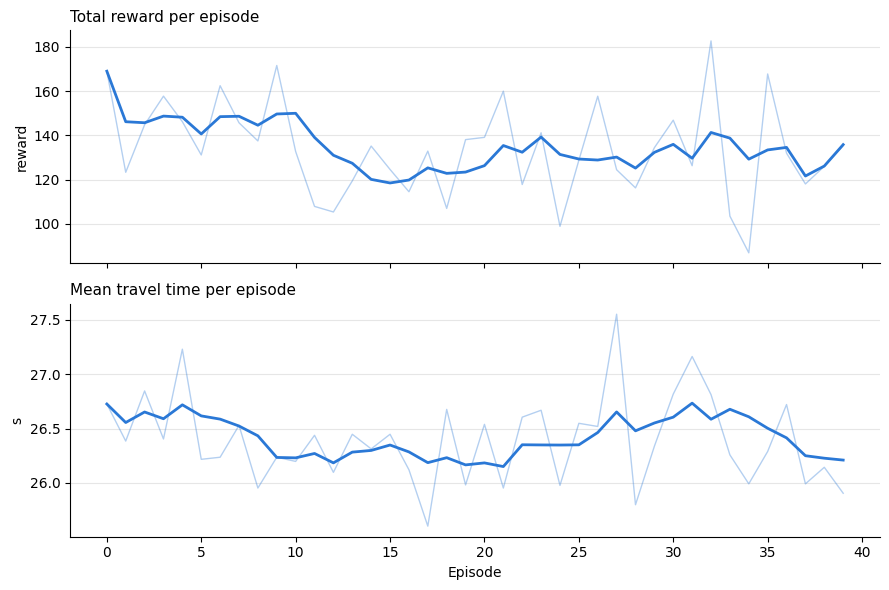

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

hist = pd.DataFrame(history)
BLUE = "#2a78d6"
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for ax, col, title, unit in [(axes[0], "total_reward", "Total reward per episode", "reward"),
                             (axes[1], "mean_travel_time", "Mean travel time per episode", "s")]:
    ax.plot(hist["episode"], hist[col], color=BLUE, linewidth=1, alpha=0.35)
    ax.plot(hist["episode"], hist[col].rolling(5, min_periods=1).mean(), color=BLUE, linewidth=2)
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_ylabel(unit)
    ax.grid(axis="y", color="0.9")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
axes[1].set_xlabel("Episode")
plt.tight_layout()
plt.show()

## 8. Evaluate: baseline vs learned policy

Same seeds for both. Baseline = no control (no platooning). Learned = greedy policy (epsilon = 0, no learning).

In [ ]:
EVAL_SEEDS = [1000, 1001, 1002, 1003, 1004]
rows = []
for seed in EVAL_SEEDS:
    for name, control in [("Baseline (no control)", False), ("Q-learning platooning", True)]:
        r = run_episode(Q, epsilon=0.0, seed=seed, learn=False, control=control)
        r.update(method=name, seed=seed)
        rows.append(r)

ev = pd.DataFrame(rows)
summary = ev.groupby("method")[["arrived", "mean_travel_time", "collisions"]].agg(["mean", "std"]).round(1)
summary

In [ ]:
means = ev.groupby("method")["mean_travel_time"].mean()
stds = ev.groupby("method")["mean_travel_time"].std()
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(means.index, means.values, yerr=stds.values, color=["#9aa0a6", BLUE], width=0.5, capsize=4)
ax.set_title("Mean travel time (lower is better)", loc="left", fontsize=11)
ax.set_ylabel("s")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 9. Watch the learned policy (optional)

Light blue = agent, purple = agent in platoon mode, red = accident.

In [ ]:
WATCH = False
if WATCH:
    run_episode(Q, epsilon=0.0, seed=2000, learn=False, control=True, use_gui=True, gui_delay=100)

## 10. Look inside the Q-table (optional)
Best action for each visited state. State = (distance bin, in blocked lane, speed bin, gap bin, in platoon).

In [ ]:
policy = pd.DataFrame(
    [{"state": s, "best_action": ACTIONS[max(range(len(ACTIONS)), key=lambda a: q[a])],
      **{a: round(q[i], 2) for i, a in enumerate(ACTIONS)}} for s, q in Q.items()]
).sort_values("state")
policy